# ASQCI advantage under noise

## Setup

In [1]:
import itertools
import numpy as np
from scipy.linalg import eigh
from scipy.optimize import minimize
from scipy.sparse import csr_matrix
from openfermion import FermionOperator, MolecularData, get_sparse_operator, jordan_wigner, normal_ordered
from openfermionpyscf import run_pyscf

import matplotlib.pyplot as plt, scienceplots, time
plt.style.use(["science"])

In [2]:
"""Seed."""
rng = np.random.default_rng(1)

### Helper functions

In [3]:
"""Hamiltonian construction/problem definition."""
def molecular_hamiltonian(geometry, basis="sto-3g", multiplicity=1, charge=0):
    molecule = run_pyscf(MolecularData(geometry, basis, multiplicity, charge), run_fci=True)
    return molecule.get_molecular_hamiltonian(), molecule.n_electrons, molecule.n_qubits, molecule.fci_energy

In [4]:
"""Fermionic ADAPT-VQE (spin-complemented UCCSD pool) in the fixed (N, Sz) sector."""
def sector_basis(n_qubits, n_electrons):
    alpha, beta = range(0, n_qubits, 2), range(1, n_qubits, 2)
    states = []
    for occ_alpha in itertools.combinations(alpha, n_electrons // 2):
        for occ_beta in itertools.combinations(beta, n_electrons - n_electrons // 2):
            states.append(sum(1 << (n_qubits - 1 - q) for q in occ_alpha + occ_beta))
    return np.array(sorted(states))


def restrict(operator, n_qubits, basis_states):
    return csr_matrix(get_sparse_operator(operator, n_qubits)[basis_states][:, basis_states])


def uccsd_pool(n_qubits, n_electrons, generalized=False):
    occupied, virtual = (range(n_qubits), range(n_qubits)) if generalized else (range(n_electrons), range(n_electrons, n_qubits))
    generators = {}
    for a in virtual:
        for i in occupied:
            if (a - i) % 2 == 0 and a > i:
                key = (a // 2, i // 2)
                generators.setdefault(key, FermionOperator())
                generators[key] += FermionOperator(((a, 1), (i, 0))) - FermionOperator(((i, 1), (a, 0)))
    for a, b in itertools.combinations(virtual, 2):
        for i, j in itertools.combinations(occupied, 2):
            if (a + b - i - j) % 2 == 0 and (a % 2 + b % 2) == (i % 2 + j % 2) and (a, b) > (i, j):
                key = (a // 2, b // 2, i // 2, j // 2, a % 2 == b % 2)
                generators.setdefault(key, FermionOperator())
                generators[key] += FermionOperator(((a, 1), (b, 1), (j, 0), (i, 0))) - FermionOperator(((i, 1), (j, 1), (b, 0), (a, 0)))
    return [normal_ordered(g) for g in generators.values() if normal_ordered(g) != FermionOperator()]


class AdaptVQE:
    def __init__(self, hamiltonian_matrix, pool_matrices, reference_index):
        self.hamiltonian = hamiltonian_matrix
        self.pool = pool_matrices
        self.reference = np.zeros(hamiltonian_matrix.shape[0]); self.reference[reference_index] = 1.0
        self.chosen, self.angles, self.states, self.energies = [], np.zeros(0), [], []

    def evolve(self, angles):
        state = self.reference
        for operator, angle in zip(self.chosen, angles):
            state = _apply_exp(self.pool[operator], angle, state)
        return state

    def energy_and_gradient(self, angles):
        forward, state = [self.reference], self.reference
        for operator, angle in zip(self.chosen, angles):
            state = _apply_exp(self.pool[operator], angle, state); forward.append(state)
        bra = self.hamiltonian @ state
        energy, gradient = float(np.real(state.conj() @ bra)), np.zeros(len(angles))
        for k in range(len(angles) - 1, -1, -1):
            gradient[k] = 2 * np.real(bra.conj() @ (self.pool[self.chosen[k]] @ forward[k + 1]))
            bra = _apply_exp(self.pool[self.chosen[k]], -angles[k], bra)
        return energy, gradient

    def run(self, max_iterations, gradient_tolerance=1e-4):
        for _ in range(max_iterations):
            state = self.evolve(self.angles)
            bra = self.hamiltonian @ state
            pool_gradients = np.array([2 * np.real(bra.conj() @ (op @ state)) for op in self.pool])
            if np.linalg.norm(pool_gradients) < gradient_tolerance:
                break
            self.chosen.append(int(np.argmax(np.abs(pool_gradients))))
            result = minimize(self.energy_and_gradient, np.append(self.angles, 0.0), jac=True, method="BFGS", options={"gtol": 1e-7})
            self.angles = result.x
            self.states.append(self.evolve(self.angles)); self.energies.append(result.fun)
        return np.array(self.states), np.array(self.energies)


def _apply_exp(anti_hermitian, angle, vector):
    result, term = vector.copy(), vector.copy()
    for order in range(1, 60):
        term = (angle / order) * (anti_hermitian @ term)
        result = result + term
        if np.linalg.norm(term) < 1e-14:
            break
    return result


def run_adapt(name, geometry, max_iterations):
    hamiltonian, n_electrons, n_qubits, fci = molecular_hamiltonian(geometry)
    basis_states = sector_basis(n_qubits, n_electrons)
    hamiltonian_matrix = restrict(jordan_wigner(hamiltonian), n_qubits, basis_states)
    pool = [restrict(jordan_wigner(g), n_qubits, basis_states) for g in uccsd_pool(n_qubits, n_electrons, generalized=True)]
    hf_index = int(np.argmax(basis_states))
    states, energies = AdaptVQE(hamiltonian_matrix, pool, hf_index).run(max_iterations, gradient_tolerance=1e-6)
    print(f"{name}: {n_qubits} qubits, sector dim {len(basis_states)}, {len(states)} ADAPT iterations, final error {1e3*(energies[-1]-fci):.3f} mHa")
    return dict(name=name, hamiltonian=hamiltonian_matrix.toarray(), probs=np.abs(states)**2, fci=fci, hf_index=hf_index, energies=energies)

In [5]:
"""ASQCI and QSCI."""
def load(path):
    data = np.load(path)
    probs = np.abs(data["states"]) ** 2  # (iterations, configs)
    return data["hamiltonian"], probs, float(data["fci"]), int(data["hf_index"])


def subspace_energy(hamiltonian, mask):
    index = np.flatnonzero(mask)
    return eigh(hamiltonian[np.ix_(index, index)], eigvals_only=True, subset_by_index=[0, 0])[0]


def first_hit_table(probs, layer_fidelity, max_shots, trials):
    """first_hit[trial, circuit, config]: index of the first surviving shot that returns config (max_shots if none)."""
    iterations, configs = probs.shape
    table = np.full((trials, iterations, configs), max_shots, dtype=np.int32)
    for j in range(iterations):
        survive = layer_fidelity ** (j + 1)
        outcome_probs = np.append(survive * probs[j], 1 - survive)
        for t in range(trials):
            outcomes = rng.choice(configs + 1, size=max_shots, p=outcome_probs)
            hits = outcomes < configs
            np.minimum.at(table[t, j], outcomes[hits], np.flatnonzero(hits))
    return table


def policy_errors(hamiltonian, probs, fci, hf_index, layer_fidelity, shots_per_circuit, trials, iterations=None):
    """Mean +- SE of energy error for pooled, endpoint, and every single depth, at each K (paired trials)."""
    iterations = iterations or probs.shape[0]
    table = first_hit_table(probs[:iterations], layer_fidelity, shots_per_circuit * iterations, trials)
    table[:, :, hf_index] = 0
    pooled, endpoint, single = np.zeros((trials, iterations)), np.zeros((trials, iterations)), np.zeros((trials, iterations, iterations))
    for t in range(trials):
        for K in range(1, iterations + 1):
            pooled[t, K - 1] = subspace_energy(hamiltonian, (table[t, :K] < shots_per_circuit).any(axis=0))
            for j in range(1, K + 1):
                single[t, K - 1, j - 1] = subspace_energy(hamiltonian, table[t, j - 1] < shots_per_circuit * K)
            endpoint[t, K - 1] = single[t, K - 1, K - 1]
    best_depth = np.array([np.argmin(single[:, K - 1, :K].mean(axis=0)) for K in range(1, iterations + 1)])
    best = np.array([single[:, K - 1, best_depth[K - 1]] for K in range(1, iterations + 1)]).T
    summary = lambda e: ((e - fci).mean(axis=0), (e - fci).std(axis=0, ddof=1) / np.sqrt(trials))
    return dict(pooled=summary(pooled), endpoint=summary(endpoint), best=summary(best), best_depth=best_depth + 1,
                pooled_minus_endpoint=summary(pooled - endpoint + fci), pooled_minus_best=summary(pooled - best + fci))


def budget_errors(hamiltonian, probs, fci, hf_index, layer_fidelity, iterations, budgets, trials):
    """Mean energy error of pooled (budget/K per circuit) and endpoint (whole budget on circuit K) for each total budget."""
    K = iterations
    table = first_hit_table(probs[:K], layer_fidelity, max(budgets), trials)
    table[:, :, hf_index] = 0
    pooled, endpoint = np.zeros((trials, len(budgets))), np.zeros((trials, len(budgets)))
    for t in range(trials):
        for b, budget in enumerate(budgets):
            pooled[t, b] = subspace_energy(hamiltonian, (table[t, :K] < budget // K).any(axis=0))
            endpoint[t, b] = subspace_energy(hamiltonian, table[t, K - 1] < budget)
    return pooled.mean(axis=0) - fci, endpoint.mean(axis=0) - fci


def shots_to_accuracy(budgets, errors, target):
    """Log-interpolated budget at which the error curve first drops below target (nan if never)."""
    below = np.flatnonzero(errors <= target)
    if len(below) == 0:
        return np.nan
    b = below[0]
    if b == 0:
        return budgets[0]
    slope = (np.log(errors[b]) - np.log(errors[b - 1])) / (np.log(budgets[b]) - np.log(budgets[b - 1]))
    return budgets[b - 1] * np.exp((np.log(target) - np.log(errors[b - 1])) / slope)

## Problem definition

In [6]:
molecules = {
    "H2O": run_adapt("H2O", [("O", (0, 0, 0)), ("H", (0, 0.757, 0.587)), ("H", (0, -0.757, 0.587))], 250),
}

H2O: 14 qubits, sector dim 441, 250 ADAPT iterations, final error 0.000 mHa


## Run ADAPT

In [7]:
for mol in molecules.values():
    probs, H = mol["probs"], mol["hamiltonian"]
    ground = np.abs(np.linalg.eigh(H)[1][:, 0])**2; ground[mol["hf_index"]] = 0
    ratio = probs.mean(axis=0) / np.maximum(probs[-1], 1e-300)
    heavy = ground > 1e-5
    kappa = np.array([(probs[j:, z] / probs[-1, z]).min() for z in np.flatnonzero(heavy) for j in [np.argmax(probs[:, z] > 0.1 * probs[-1, z])]])

## Run ASQCI and QCSI

In [8]:
mol = molecules["H2O"]
r = policy_errors(mol["hamiltonian"], mol["probs"], mol["fci"], mol["hf_index"], layer_fidelity=0.99, shots_per_circuit=100, trials=256)

## Plot results

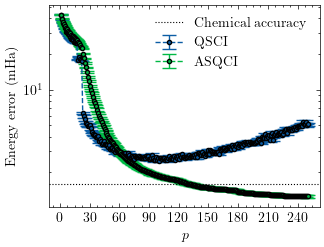

In [12]:
K = np.arange(1, len(mol["probs"]) + 1)
fig, ax_energy = plt.subplots()
for key, label, ls in [("endpoint", "QSCI", "--"), ("pooled", "ASQCI", "--")]:
    ax_energy.errorbar(K, 1e3 * r[key][0], yerr=1e3 * r[key][1], marker="o", mec="black", ms=3, capsize=5, ls=ls, label=label)
ax_energy.axhline(1.6, color="k", ls=":", lw=0.8, label="Chemical accuracy")
ax_energy.set(yscale="log", xlabel="$p$", ylabel="Energy error (mHa)")
ax_energy.legend()
for ax in (ax_energy,):
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.savefig("h2o.pdf")